In [1]:
import seaborn as sns
# Load the 'taxis' dataset
df = sns.load_dataset("taxis")

In [2]:
import pandas as pd
import seaborn as sns

df = sns.load_dataset("taxis")

# 1) Check for missing values
missing = df.isnull().sum()
print("Missing values per column:")
print(missing[missing > 0])

print("\nPercentage missing:")
print((df.isnull().mean() * 100).round(2)[missing > 0])

# 2) Impute missing values based on column type
num_cols = df.select_dtypes(include="number").columns
cat_cols = df.select_dtypes(exclude="number").columns

# Numerical columns: median (robust to outliers like large fares/tolls)
for col in num_cols:
    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].median())

# Categorical columns: mode
# (skip the pickup/dropoff timestamps, which are datetime, and handle below)
for col in cat_cols:
    if col in ["pickup", "dropoff"]:
        continue
    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].mode()[0])

# 3) Drop rows where critical columns are still missing
# Timestamps can't be reasonably imputed
df = df.dropna(subset=["pickup", "dropoff"])

# Verify
print("\nMissing values after cleaning:")
print(df.isnull().sum())
print("\nFinal shape:", df.shape)

Missing values per column:
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64

Percentage missing:
payment            0.68
pickup_zone        0.40
dropoff_zone       0.70
pickup_borough     0.40
dropoff_borough    0.70
dtype: float64

Missing values after cleaning:
pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64

Final shape: (6433, 14)


In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = sns.load_dataset("taxis")

# Convert timestamps to datetime
df["pickup"] = pd.to_datetime(df["pickup"])
df["dropoff"] = pd.to_datetime(df["dropoff"])

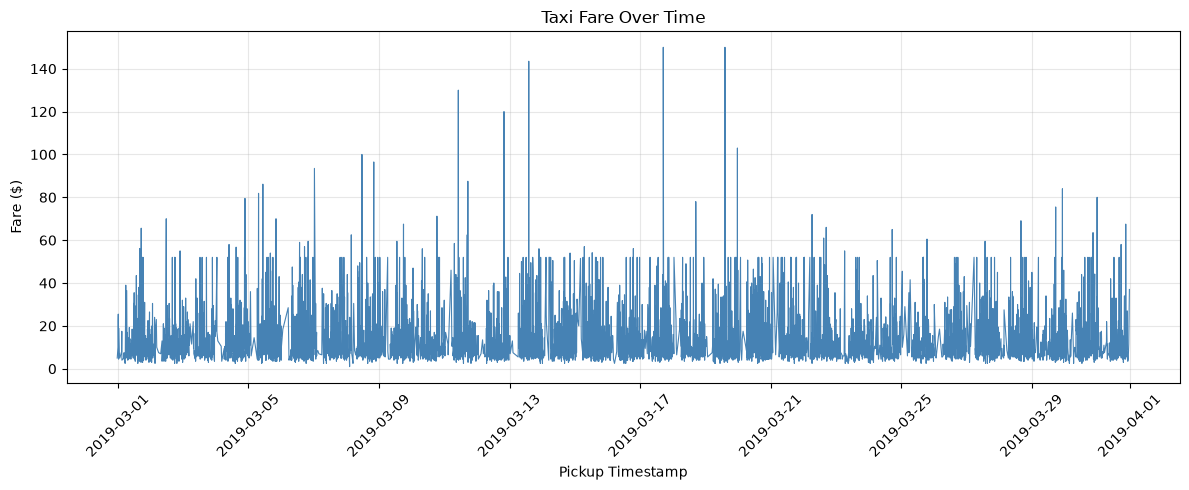

In [6]:
line_df = df.sort_values("pickup")

plt.figure(figsize=(12, 5))
plt.plot(line_df["pickup"], line_df["fare"], color="steelblue", linewidth=0.8)
plt.title("Taxi Fare Over Time")
plt.xlabel("Pickup Timestamp")
plt.ylabel("Fare ($)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

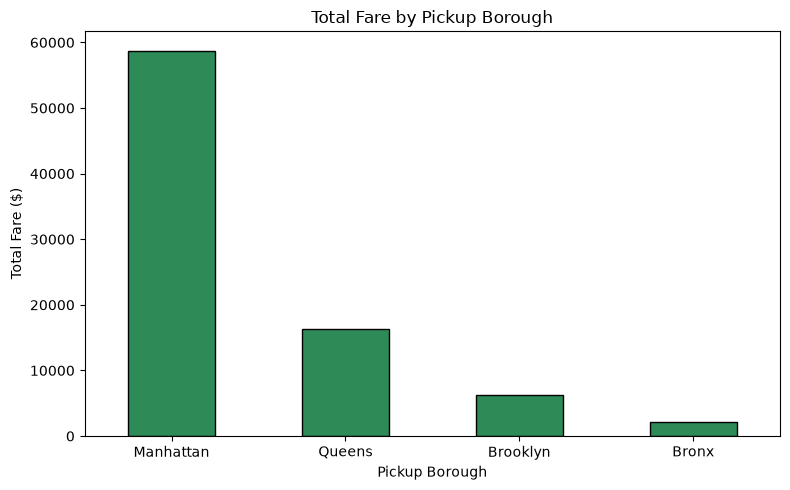

In [7]:
borough_fare = df.groupby("pickup_borough")["fare"].sum().sort_values(ascending=False)

plt.figure(figsize=(8, 5))
borough_fare.plot(kind="bar", color="seagreen", edgecolor="black")
plt.title("Total Fare by Pickup Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Total Fare ($)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

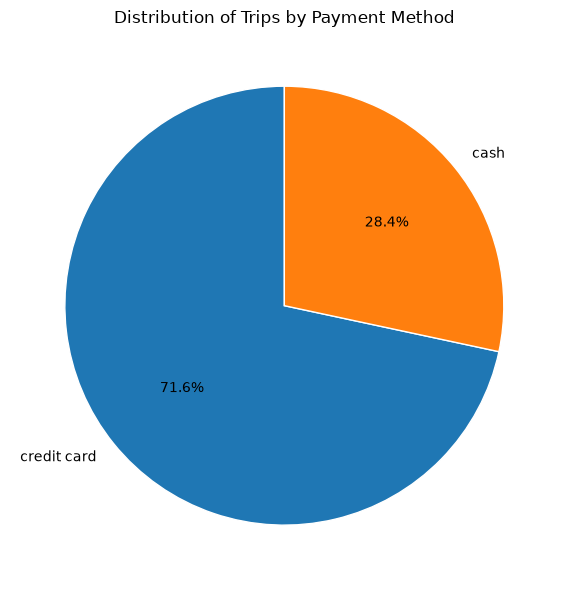

In [8]:
payment_counts = df["payment"].value_counts()

plt.figure(figsize=(6, 6))
payment_counts.plot(
    kind="pie",
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"edgecolor": "white"},
)
plt.title("Distribution of Trips by Payment Method")
plt.ylabel("")
plt.tight_layout()
plt.show()

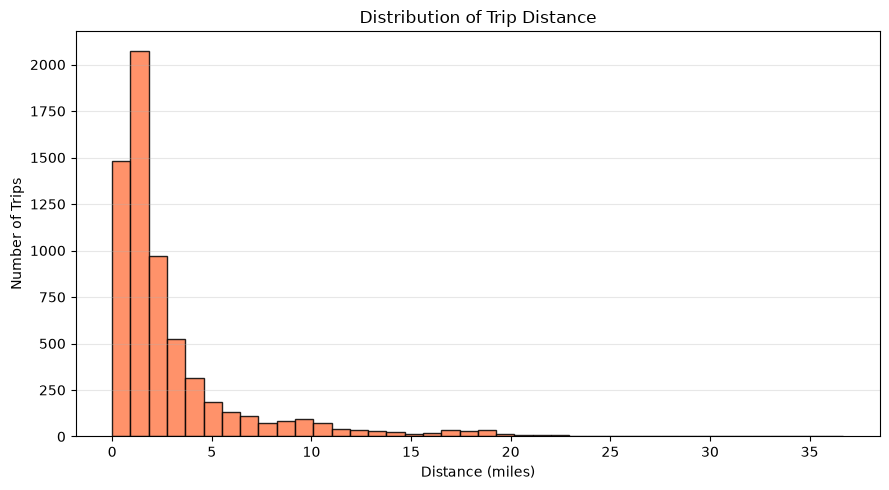

In [9]:
plt.figure(figsize=(9, 5))
plt.hist(df["distance"], bins=40, color="coral", edgecolor="black", alpha=0.85)
plt.title("Distribution of Trip Distance")
plt.xlabel("Distance (miles)")
plt.ylabel("Number of Trips")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

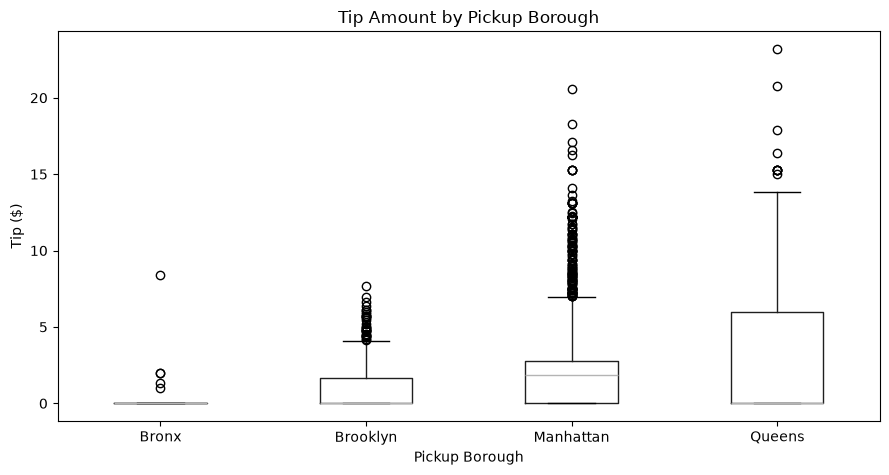

In [10]:
df.boxplot(column="tip", by="pickup_borough", grid=False, figsize=(9, 5))
plt.title("Tip Amount by Pickup Borough")
plt.suptitle("")
plt.xlabel("Pickup Borough")
plt.ylabel("Tip ($)")
plt.tight_layout()
plt.show()

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = sns.load_dataset("taxis")
df["pickup"] = pd.to_datetime(df["pickup"])
df["dropoff"] = pd.to_datetime(df["dropoff"])

C:\Users\SOORA\AppData\Local\Temp\ipykernel_17300\2822292253.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="pickup_borough", order=df["pickup_borough"].value_counts().index, palette="viridis")


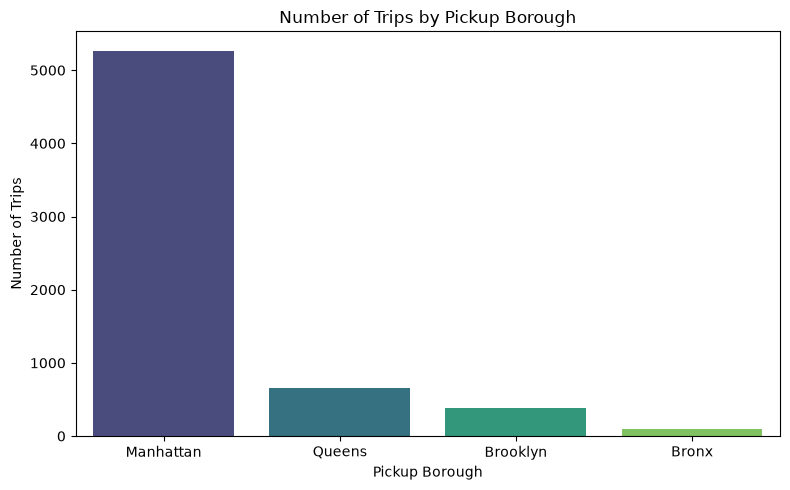

In [12]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="pickup_borough", order=df["pickup_borough"].value_counts().index, palette="viridis")
plt.title("Number of Trips by Pickup Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Number of Trips")
plt.tight_layout()
plt.show()

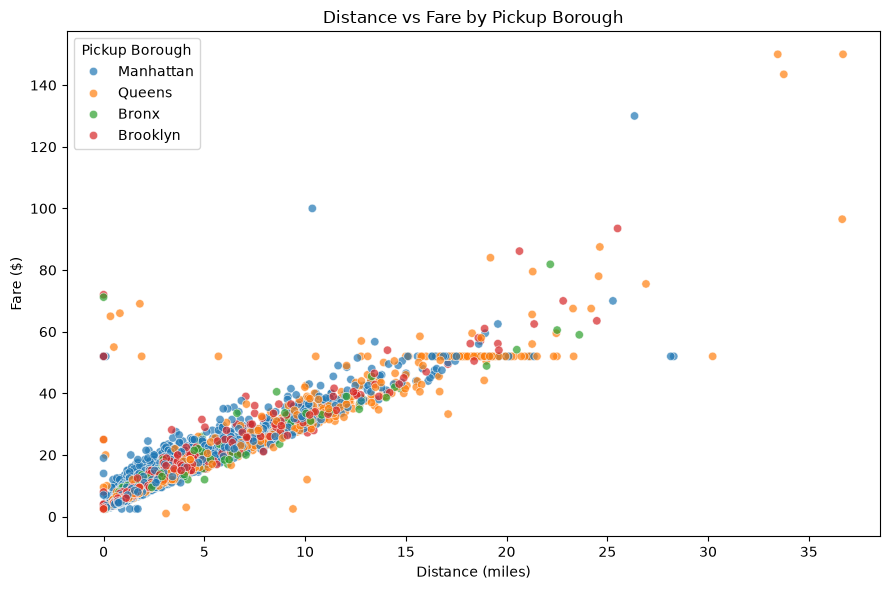

In [13]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x="distance", y="fare", hue="pickup_borough", alpha=0.7)
plt.title("Distance vs Fare by Pickup Borough")
plt.xlabel("Distance (miles)")
plt.ylabel("Fare ($)")
plt.legend(title="Pickup Borough")
plt.tight_layout()
plt.show()

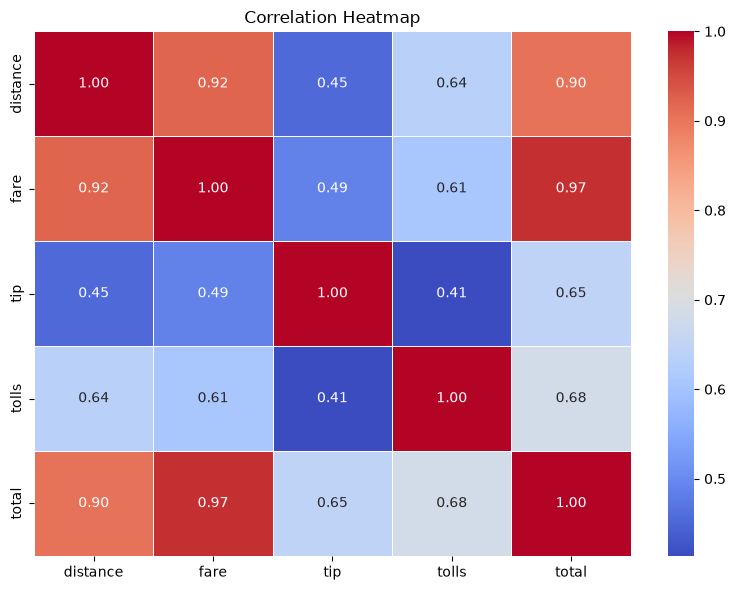

In [14]:
corr = df[["distance", "fare", "tip", "tolls", "total"]].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

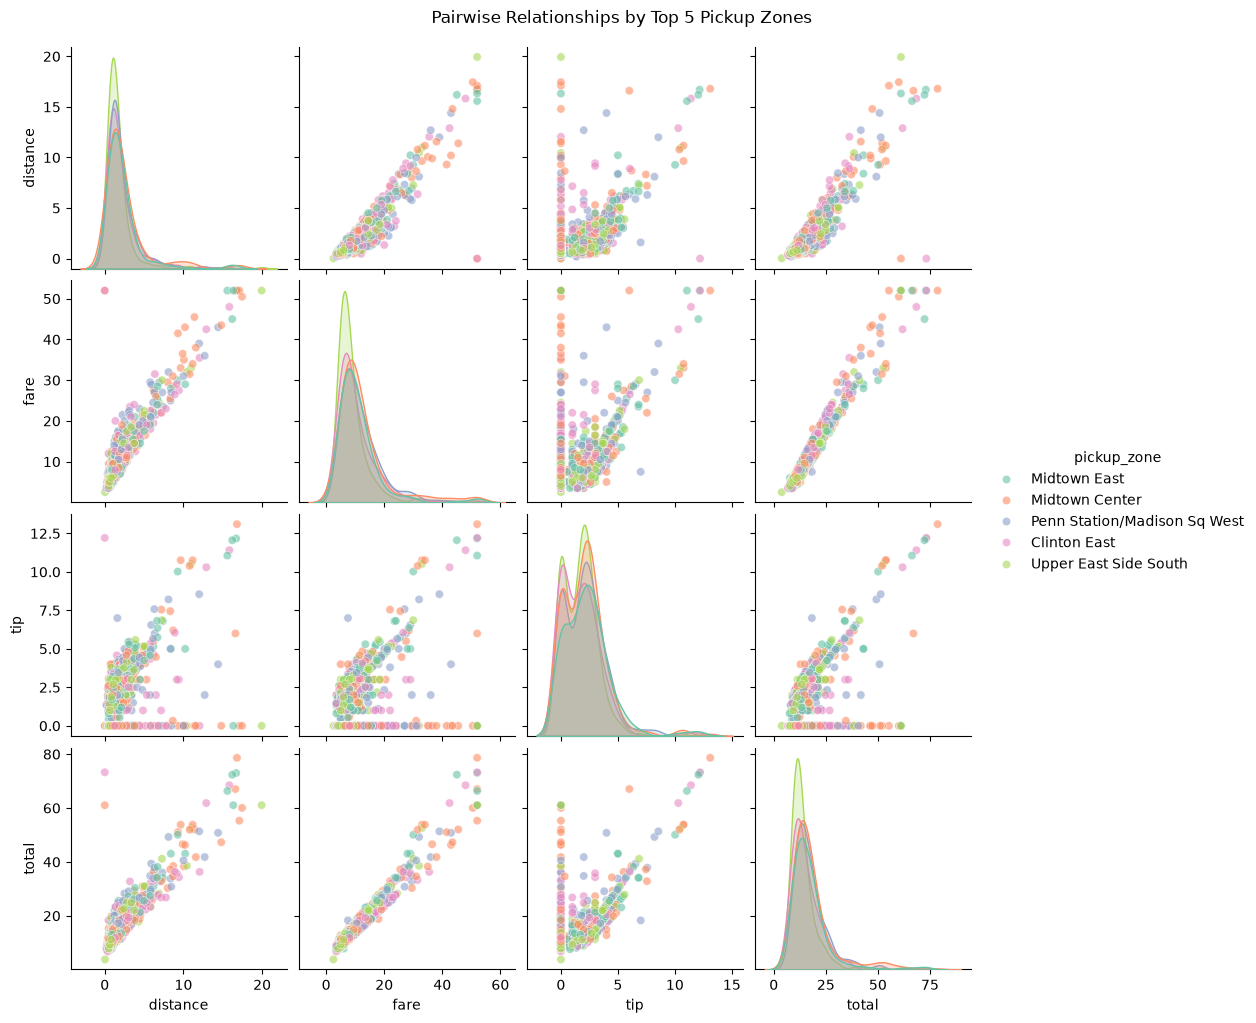

In [15]:
top_zones = df["pickup_zone"].value_counts().head(5).index
subset = df[df["pickup_zone"].isin(top_zones)]

sns.pairplot(
    subset,
    vars=["distance", "fare", "tip", "total"],
    hue="pickup_zone",
    palette="Set2",
    plot_kws={"alpha": 0.6},
)
plt.suptitle("Pairwise Relationships by Top 5 Pickup Zones", y=1.02)
plt.show()